#  03 — Análisis Exploratorio Bivariado (EDA)
**Objetivo:** Explorar relaciones no lineales entre pares de indicadores demográficos, evaluar correlaciones de Spearman, filtrar redundancias críticas ($|\rho| > 0.90$) y contrastar empíricamente las hipótesis de transición demográfica por continente y época.

**Input:** `data/silver/wpp2024_countries_estimates.parquet`  
**Output:** Criterios empíricos de selección para el Índice Compuesto (Notebook 04) y figuras en `outputs/figures/eda/`.

---

## 3.1 Imports, configuración y carga de datos Silver
Cargamos las estimaciones históricas (1950–2023) a nivel de países y áreas (`LocTypeID == 4`), asignamos la correspondencia geográfica oficial M49 de la ONU y configuramos la visualización colorblind-friendly.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Configuración de rutas y estilos
sys.path.insert(0, str(Path.cwd().parent))
from src.config import SILVER, FIGURES_EDA
from src.viz import setup_style, save_figure

setup_style()

# Cargar estimaciones Silver (1950-2023)
df = pd.read_parquet(SILVER / 'wpp2024_countries_estimates.parquet')

# Mapeo oficial de regiones UN M49 (ParentID a Continente)
region_map = {
    910: 'Africa', 911: 'Africa', 912: 'Africa', 913: 'Africa', 914: 'Africa',
    5500: 'Asia', 906: 'Asia', 5501: 'Asia', 920: 'Asia', 922: 'Asia',
    923: 'Europe', 924: 'Europe', 925: 'Europe', 926: 'Europe',
    915: 'Latin America & Caribbean', 916: 'Latin America & Caribbean', 931: 'Latin America & Caribbean',
    918: 'Northern America',
    927: 'Oceania', 928: 'Oceania', 954: 'Oceania', 957: 'Oceania'
}
df['Continent'] = df['ParentID'].map(region_map)

print(f"Dimensiones cargadas: {df.shape[0]:,} observaciones x {df.shape[1]} columnas")
print(f"Localidades únicas: {df['Location'].nunique()} | Periodo: {df['Time'].min()} - {df['Time'].max()}")

Dimensiones cargadas: 17,538 observaciones x 77 columnas
Localidades únicas: 237 | Periodo: 1950 - 2023


## 3.2 Matriz de correlaciones Spearman y filtro de colinealidad
Para diseñar el **Índice Compuesto Demográfico**, no debemos incluir variables fuertemente colineales que distorsionen los pesos factoriales del PCA.
* Usamos la correlación de rangos de **Spearman** ($\rho$), ya que captura relaciones monótonas no lineales y es robusta frente a las asimetrías y colas pesadas de las variables demográficas.
* **Criterio metodológico:** Todo par con $|\rho| > 0.90$ será analizado para descartar la variable redundante.

   Saved: outputs\figures\eda\03_correlation_matrix_spearman.png


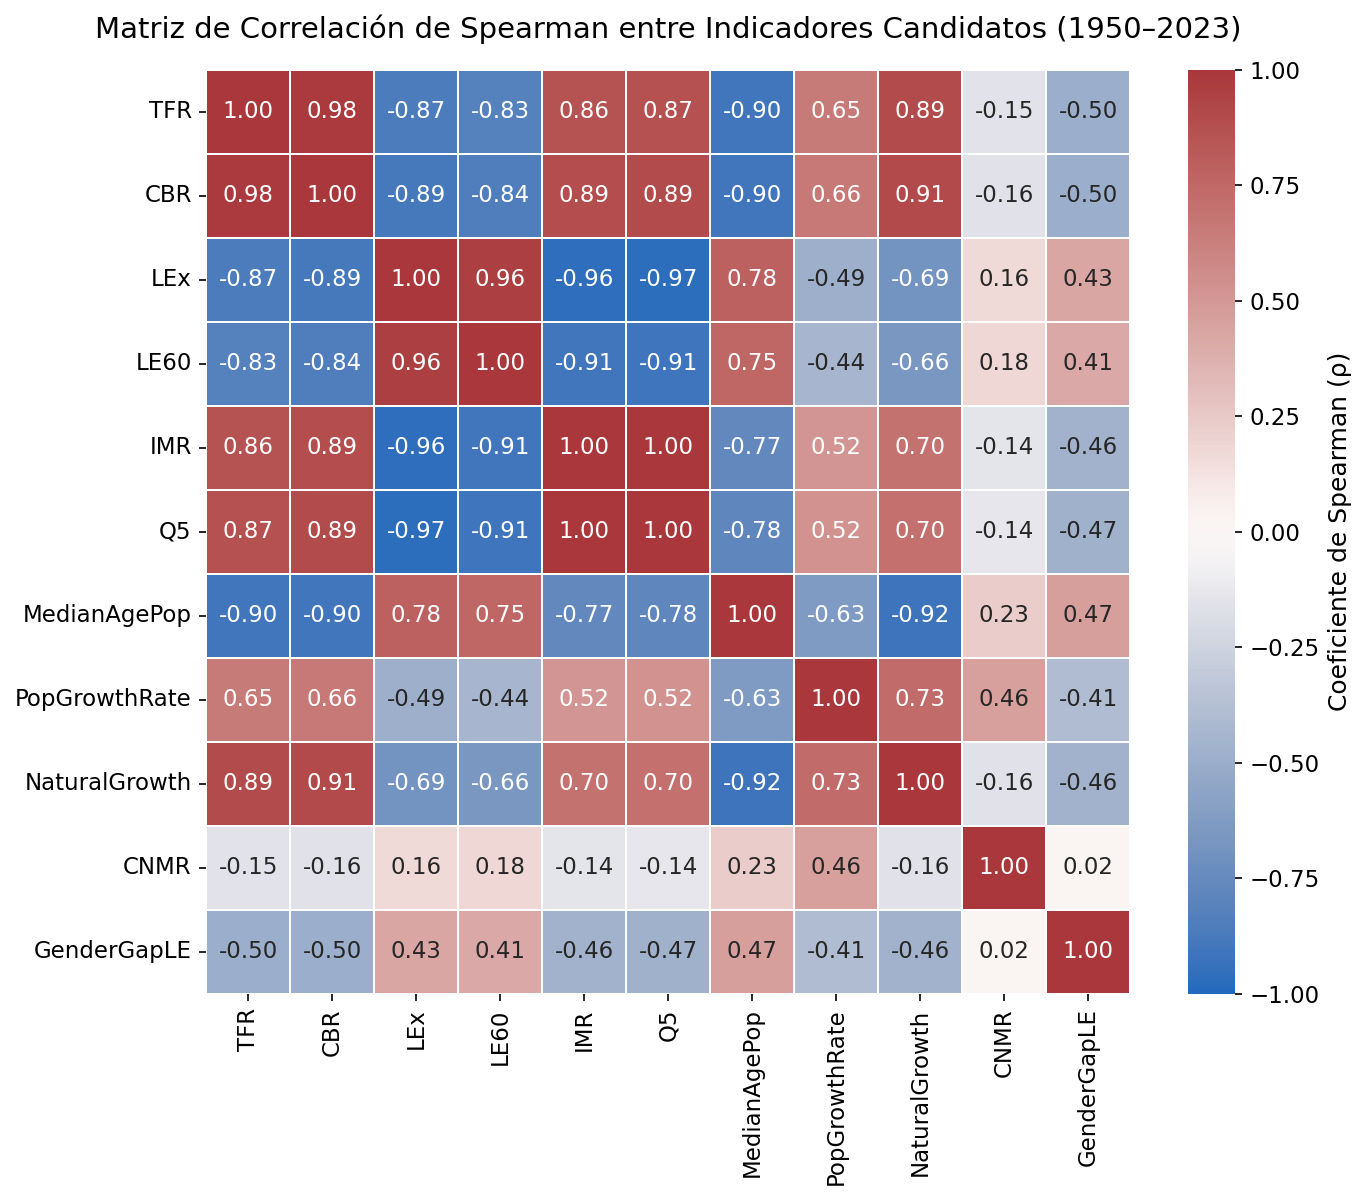

Pares con colinealidad extrema (|rho| > 0.90):


,Variable 1,Variable 2,Spearman_rho
0,TFR,CBR,0.978
1,CBR,MedianAgePop,-0.901
2,CBR,NaturalGrowth,0.905
3,LEx,LE60,0.960
4,LEx,IMR,-0.965
5,LEx,Q5,-0.971
6,LE60,IMR,-0.906
7,LE60,Q5,-0.908
8,IMR,Q5,0.998
9,MedianAgePop,NaturalGrowth,-0.919


In [2]:
# Selección de variables representativas de los pilares demográficos
candidate_vars = [
    'TFR', 'CBR', 'LEx', 'LE60', 'IMR', 'Q5', 
    'MedianAgePop', 'PopGrowthRate', 'NaturalGrowth', 'CNMR', 'GenderGapLE'
]

# Matriz de Spearman
corr_spearman = df[candidate_vars].corr(method='spearman')

# Visualización: Heatmap
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr_spearman, 
    annot=True, 
    fmt='.2f', 
    cmap='vlag', 
    center=0, 
    vmin=-1, 
    vmax=1, 
    square=True, 
    linewidths=0.8, 
    cbar_kws={'label': 'Coeficiente de Spearman (ρ)'},
    ax=ax
)
ax.set_title("Matriz de Correlación de Spearman entre Indicadores Candidatos (1950–2023)", pad=15)
save_figure(fig, "03_correlation_matrix_spearman")
plt.show()

# Detección programática de colinealidades críticas (|rho| > 0.90)
collinear_pairs = []
for i in range(len(candidate_vars)):
    for j in range(i+1, len(candidate_vars)):
        v1, v2 = candidate_vars[i], candidate_vars[j]
        val = corr_spearman.loc[v1, v2]
        if abs(val) > 0.90:
            collinear_pairs.append({'Variable 1': v1, 'Variable 2': v2, 'Spearman_rho': round(val, 3)})

df_collinear = pd.DataFrame(collinear_pairs)
print("Pares con colinealidad extrema (|rho| > 0.90):")
display(df_collinear)

### Hallazgos y Decisiones Metodológicas de Colinealidad:
1. **Fecundidad (`TFR` vs `CBR`, $\rho = +0.98$):** Ambas miden natalidad, pero la Tasa Bruta (`CBR`) depende de la estructura de edad, mientras que `TFR` es la métrica demográfica estándar independiente de la pirámide etaria.  
   **Decisión:** Conservar **`TFR`** y excluir `CBR`.
2. **Mortalidad en la niñez (`IMR` vs `Q5`, $\rho = +1.00$):** La mortalidad infantil ($<1$ año) y de la niñez ($<5$ años) son casi idénticas en rangos.  
   **Decisión:** Conservar **`IMR`** (estándar canónico OMS/UNICEF) y excluir `Q5`.
3. **Supervivencia vs Salud Temprana (`LEx` vs `IMR`, $\rho = -0.96$):** Fuerte relación inversa esperada: reducir la mortalidad de menores impulsa automáticamente la longevidad al nacer.  
   **Decisión:** Conservar **`LEx`** como eje central de supervivencia y evaluar **`LE60`** para longevidad geriátrica en la vejez.
4. **Independencia de la Migración (`CNMR`):** La tasa neta de migración tiene correlaciones muy bajas con todos los indicadores vegetativos ($|\rho| < 0.20$), confirmando que la migración aporta una **dimensión ortogonal indispensable**.

## 3.3 Scatter: TFR vs Esperanza de Vida ($LEx$) — La Curva de Transición Demográfica
Examinamos la relación canónica entre fecundidad y longevidad contrastando cuatro momentos históricos (1950, 1980, 2000 y 2023).

   Saved: outputs\figures\eda\03_scatter_tfr_vs_lex_epochs.png


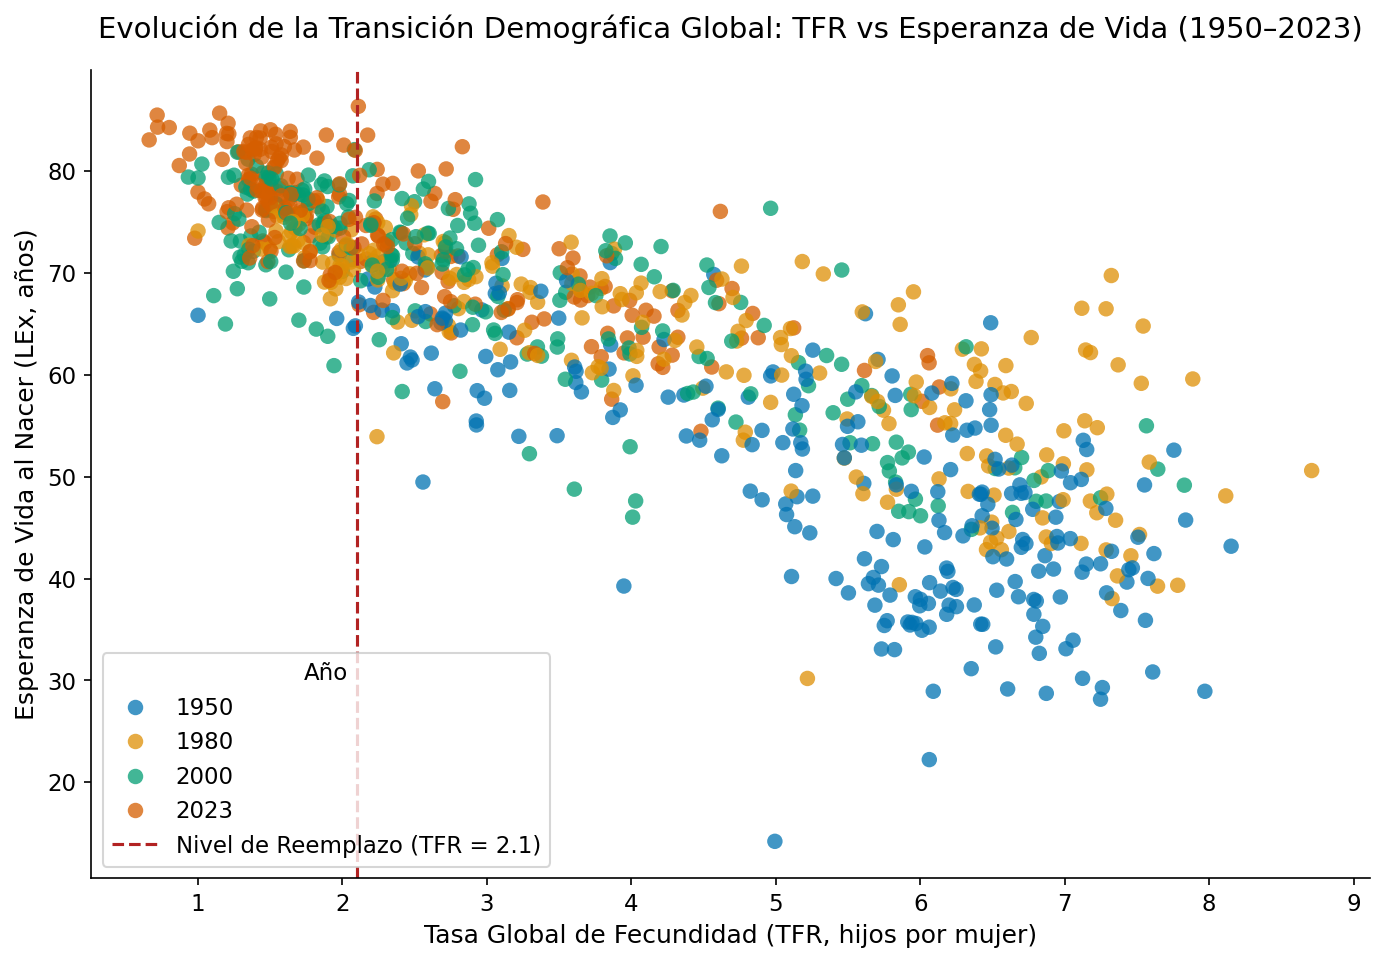

In [3]:
epochs_to_plot = [1950, 1980, 2000, 2023]
df_epochs = df[df['Time'].isin(epochs_to_plot)].copy()

fig, ax = plt.subplots(figsize=(11, 7))

palette = sns.color_palette("colorblind", n_colors=len(epochs_to_plot))
sns.scatterplot(
    data=df_epochs,
    x='TFR',
    y='LEx',
    hue='Time',
    palette=palette,
    alpha=0.75,
    s=55,
    edgecolor='none',
    ax=ax
)

# Umbral crítico de reemplazo generacional (2.1)
ax.axvline(2.1, color='firebrick', linestyle='--', linewidth=1.5, label='Nivel de Reemplazo (TFR = 2.1)')

ax.set_title("Evolución de la Transición Demográfica Global: TFR vs Esperanza de Vida (1950–2023)", pad=15)
ax.set_xlabel("Tasa Global de Fecundidad (TFR, hijos por mujer)")
ax.set_ylabel("Esperanza de Vida al Nacer (LEx, años)")
ax.legend(title="Año", loc="lower left", frameon=True)

save_figure(fig, "03_scatter_tfr_vs_lex_epochs")
plt.show()

### Hallazgos de la Curva de Transición:
* **1950 (Mundo Polarizado):** Separación tajante entre países avanzados ($LEx > 65$, $TFR < 3.5$) y el resto del mundo ($TFR > 6.0$, $LEx < 45$).
* **2023 (Desplazamiento y Divergencia de Reemplazo):** Casi la totalidad de las naciones superó los 60 años de vida media. Sin embargo, la dispersión en fecundidad no convergió en el reemplazo ($TFR \approx 2.1$):
  - Más de la mitad de las naciones cayeron en **ultra-baja fecundidad** ($TFR < 1.5$), mientras África subsahariana permanece en $TFR > 4.0$.
  - Esto desmiente la noción de un equilibrio global final homogéneo.

## 3.4 Evolución Temporal Agregada por Continente
Analizamos si las trayectorias regionales convergen o divergen en tres dimensiones clave: Fecundidad ($TFR$), Longevidad ($LEx$) y Estructura Etaria ($MedianAgePop$).

   Saved: outputs\figures\eda\03_regional_timelines.png


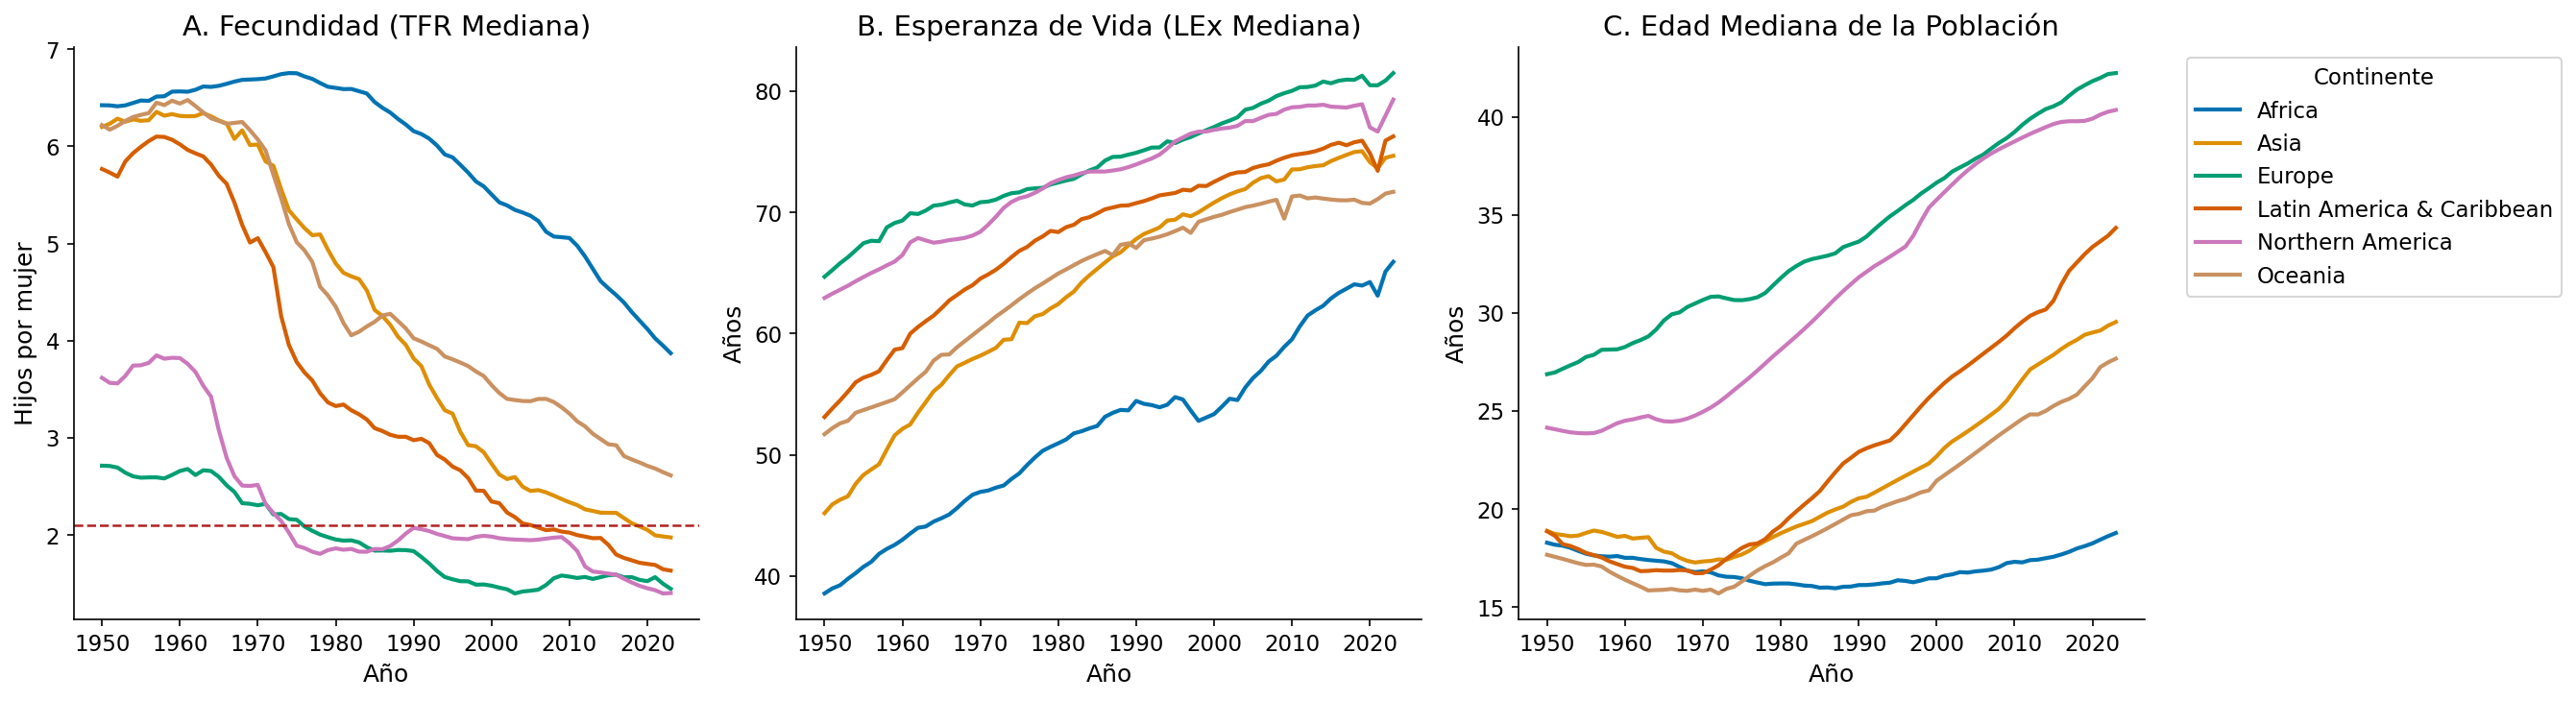

In [4]:
# Mediana por continente y año
df_regional = df.groupby(['Continent', 'Time'])[['TFR', 'LEx', 'MedianAgePop']].median().reset_index()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. TFR
sns.lineplot(data=df_regional, x='Time', y='TFR', hue='Continent', ax=axes[0], legend=False, linewidth=2)
axes[0].axhline(2.1, color='firebrick', linestyle='--', linewidth=1.2, label='Reemplazo (2.1)')
axes[0].set_title("A. Fecundidad (TFR Mediana)")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Hijos por mujer")

# 2. LEx
sns.lineplot(data=df_regional, x='Time', y='LEx', hue='Continent', ax=axes[1], legend=False, linewidth=2)
axes[1].set_title("B. Esperanza de Vida (LEx Mediana)")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("Años")

# 3. MedianAgePop
sns.lineplot(data=df_regional, x='Time', y='MedianAgePop', hue='Continent', ax=axes[2], linewidth=2)
axes[2].set_title("C. Edad Mediana de la Población")
axes[2].set_xlabel("Año")
axes[2].set_ylabel("Años")
axes[2].legend(title="Continente", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)

plt.tight_layout()
save_figure(fig, "03_regional_timelines")
plt.show()

### Hallazgos de la Dinámica Regional:
* **Convergencia en Longevidad ($LEx$):** América Latina y Asia lograron una convergencia acelerada con Europa y Norteamérica (Asia ganó más de 30 años de vida media entre 1950 y 2023).
* **Divergencia Estructural en Edad Mediana ($MedianAgePop$):** A pesar de la cercanía en supervivencia, la estructura de edad diverge ampliamente:
  - Europa y Norteamérica superan los **42 años** de edad mediana.
  - África permanece por debajo de los **20 años**.
  - Esta brecha generacional de **más de 22 años** condiciona totalmente la fuerza laboral y las pensiones mundiales.

## 3.5 Brecha de Género en Esperanza de Vida (`GenderGapLE`)
Examinamos la ventaja de supervivencia femenina (`GenderGapLE = LExFemale - LExMale`) a nivel continental y su evolución histórica.

C:\Users\ADMON\AppData\Local\Temp\ipykernel_37060\1490023132.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_2023, x='Continent', y='GenderGapLE', ax=axes[0], palette='colorblind')


   Saved: outputs\figures\eda\03_gender_gap_analysis.png


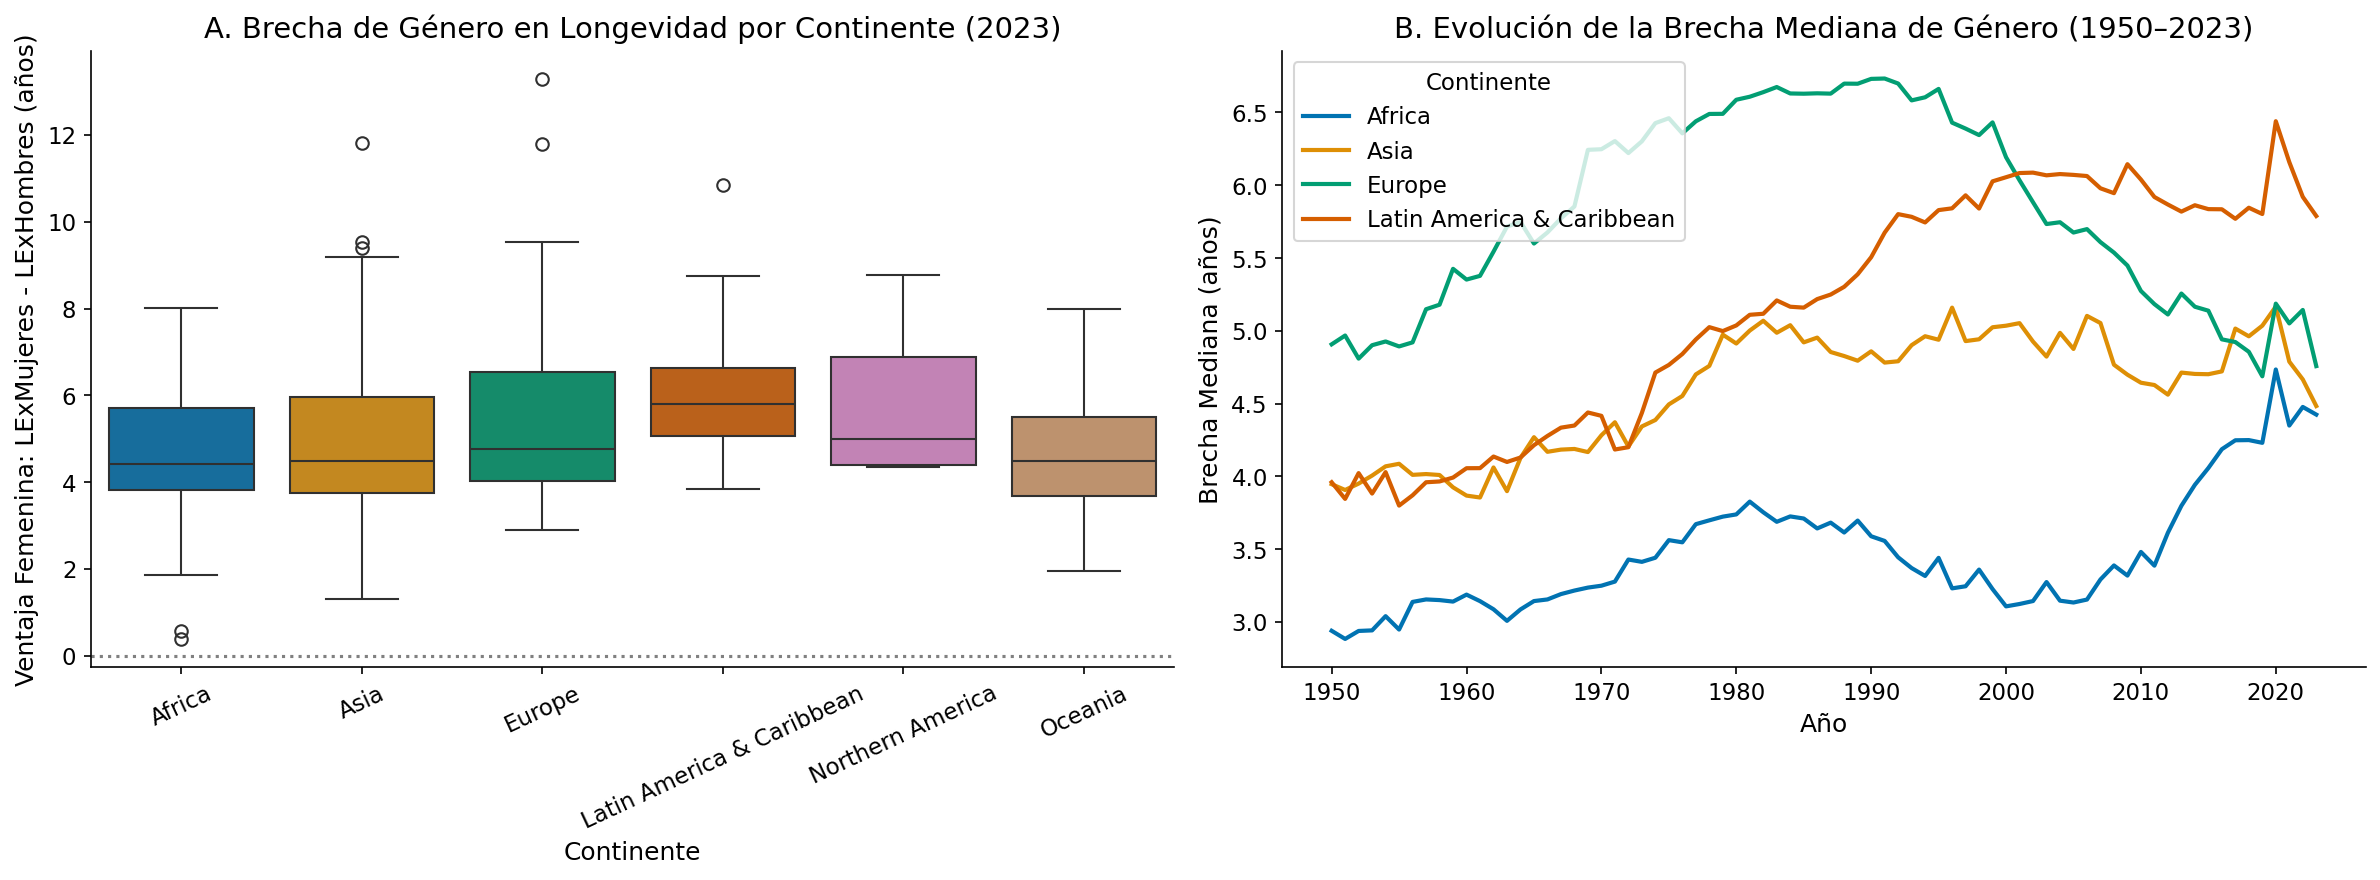

Top 5 Países con Mayor Brecha Femenina en 2023:


,Location,Continent,LExFemale,LExMale,GenderGapLE
8805,Ukraine,Europe,80.1980,66.8995,13.2985
7769,State of Palestine,Asia,71.5017,59.6910,11.8107
8657,Russian Federation,Europe,79.0375,67.2561,11.7814
13837,United States Virgin Islands,Latin America & Caribbean,81.3519,70.5129,10.8390
7103,Georgia,Asia,79.1071,69.5694,9.5377



Top 5 Países con Menor Brecha Femenina (o desventaja) en 2023:


,Location,Continent,LExFemale,LExMale,GenderGapLE
4291,Togo,Africa,62.9226,62.5356,0.3870
3995,Nigeria,Africa,54.7431,54.1760,0.5671
6955,Bahrain,Asia,81.9872,80.6723,1.3149
7621,Qatar,Asia,83.3676,81.6108,1.7568
3921,Niger,Africa,62.1293,60.2599,1.8694


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# A. Boxplot de brecha de género por continente en 2023
df_2023 = df[df['Time'] == 2023].copy()
sns.boxplot(data=df_2023, x='Continent', y='GenderGapLE', ax=axes[0], palette='colorblind')
axes[0].set_title("A. Brecha de Género en Longevidad por Continente (2023)")
axes[0].set_xlabel("Continente")
axes[0].set_ylabel("Ventaja Femenina: LExMujeres - LExHombres (años)")
axes[0].tick_params(axis='x', rotation=25)
axes[0].axhline(0, color='gray', linestyle=':')

# B. Evolución temporal de la brecha mediana
focus_regions = ['Europe', 'Asia', 'Latin America & Caribbean', 'Africa']
df_gap_time = df[df['Continent'].isin(focus_regions)].groupby(['Continent', 'Time'])['GenderGapLE'].median().reset_index()
sns.lineplot(data=df_gap_time, x='Time', y='GenderGapLE', hue='Continent', ax=axes[1], linewidth=2)
axes[1].set_title("B. Evolución de la Brecha Mediana de Género (1950–2023)")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("Brecha Mediana (años)")
axes[1].legend(title="Continente", frameon=True)

plt.tight_layout()
save_figure(fig, "03_gender_gap_analysis")
plt.show()

# Casos extremos en 2023
print("Top 5 Países con Mayor Brecha Femenina en 2023:")
display(df_2023[['Location', 'Continent', 'LExFemale', 'LExMale', 'GenderGapLE']].sort_values(by='GenderGapLE', ascending=False).head(5))

print("")
print("Top 5 Países con Menor Brecha Femenina (o desventaja) en 2023:")
display(df_2023[['Location', 'Continent', 'LExFemale', 'LExMale', 'GenderGapLE']].sort_values(by='GenderGapLE', ascending=True).head(5))

### Hallazgos de la Brecha de Género:
* **Ventaja femenina biológica y comportamental:** En prácticamente todas las regiones, las mujeres sobreviven entre 4 y 6 años más que los hombres.
* **Sobre-mortalidad masculina en Europa del Este:** La brecha supera los 10-11 años en países de la antigua órbita soviética (Rusia, Bielorrusia, Letonia), impulsada por factores ocupacionales, consumo de alcohol y crisis cardiovascular prematura masculina.
* **Evolución histórica en países de ingresos bajos:** En 1950, la brecha era cercana a 0 en el sur de Asia y partes de África por alta mortalidad materna y desnutrición infantil femenina; hoy se ha normalizado a niveles biológicos típicos.

## 3.6 Crecimiento Natural vs Compensación Migratoria (`CNMR` vs `NaturalGrowth`)
Evaluamos el balance entre crecimiento vegetativo (`NaturalGrowth = CBR - CDR`) y la tasa neta de migración (`CNMR`) para clasificar a los países en 4 cuadrantes demográficos en 2023.

   Saved: outputs\figures\eda\03_natural_growth_vs_migration.png


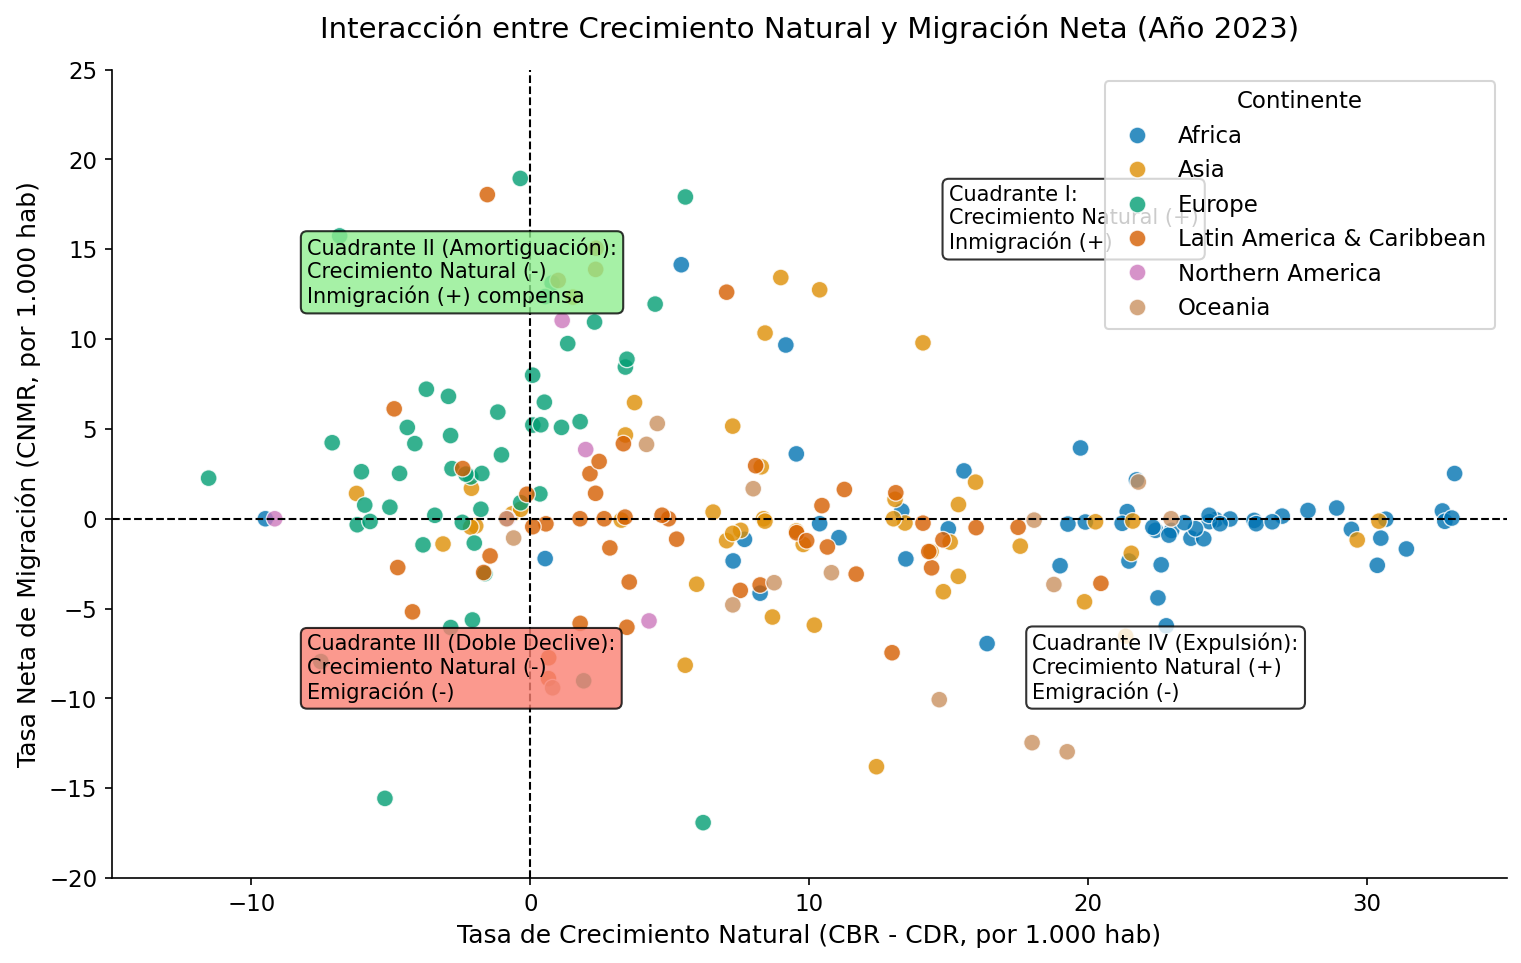

Países representativos donde la inmigración compensa el decrecimiento vegetativo (2023):


,Location,Continent,NaturalGrowth,CNMR,PopGrowthRate
11617,Monaco,Europe,-11.530,2.259,-0.922
9545,Latvia,Europe,-7.100,4.232,-0.287
9619,Lithuania,Europe,-6.834,15.744,0.891
5105,Japan,Asia,-6.228,1.407,-0.482
10137,Croatia,Europe,-6.053,2.619,-0.343
8213,Bulgaria,Europe,-5.935,0.761,-0.517


In [8]:
fig, ax = plt.subplots(figsize=(12, 7))

# Scatter en 2023
sns.scatterplot(
    data=df_2023,
    x='NaturalGrowth',
    y='CNMR',
    hue='Continent',
    palette='colorblind',
    s=65,
    alpha=0.8,
    ax=ax
)

# Ejes de referencia en cero
ax.axvline(0, color='black', linestyle='--', linewidth=1)
ax.axhline(0, color='black', linestyle='--', linewidth=1)

# Cuadrantes
ax.text(15, 15, 'Cuadrante I:\nCrecimiento Natural (+)\nInmigración (+)', fontsize=10, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax.text(-8, 12, 'Cuadrante II (Amortiguación):\nCrecimiento Natural (-)\nInmigración (+) compensa', fontsize=10, bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.8))
ax.text(-8, -10, 'Cuadrante III (Doble Declive):\nCrecimiento Natural (-)\nEmigración (-)', fontsize=10, bbox=dict(boxstyle='round', facecolor='salmon', alpha=0.8))
ax.text(18, -10, 'Cuadrante IV (Expulsión):\nCrecimiento Natural (+)\nEmigración (-)', fontsize=10, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_title("Interacción entre Crecimiento Natural y Migración Neta (Año 2023)", pad=15)
ax.set_xlabel("Tasa de Crecimiento Natural (CBR - CDR, por 1.000 hab)")
ax.set_ylabel("Tasa Neta de Migración (CNMR, por 1.000 hab)")
ax.set_xlim(-15, 35)
ax.set_ylim(-20, 25)
ax.legend(title="Continente", loc="upper right", frameon=True)

save_figure(fig, "03_natural_growth_vs_migration")
plt.show()

# Países del Cuadrante II
buffer_countries = df_2023[(df_2023['NaturalGrowth'] < 0) & (df_2023['CNMR'] > 0)][['Location', 'Continent', 'NaturalGrowth', 'CNMR', 'PopGrowthRate']].sort_values(by='NaturalGrowth').head(6)
print("Países representativos donde la inmigración compensa el decrecimiento vegetativo (2023):")
display(buffer_countries)

###  Hallazgos de la Dinámica Migratoria:
* **Cuadrante II (Amortiguador de reemplazo):** Economías como España, Alemania, Italia o Japón tienen más muertes que nacimientos ($NaturalGrowth < 0$). La recepción neta de migrantes amortigua o revierte su despoblación.
* **Cuadrante III (Doble crisis):** Países de Europa del Este (Bulgaria, Letonia, Serbia) combinan decrecimiento natural con fuga de talento/jóvenes, acelerando el envejecimiento.
* **Justificación para el Índice:** La migración actúa como un vector corrector independiente que debe estar presente en la arquitectura del perfil demográfico del país.

## 3.7 Síntesis de Relaciones e Implicaciones para el Notebook 04 (PCA e Índice)
Consolidamos formalmente las decisiones bivariadas para la construcción del Índice Compuesto.

| Pilar | Variables Evaluadas | Decision | Justificacion |
| :--- | :--- | :--- | :--- |
| **Fecundidad** | `TFR`, `CBR` | Conservar `TFR`, excluir `CBR` | Colinealidad $\rho = 0.98$. `TFR` es independiente de la estructura por edades. |
| **Mortalidad Temprana** | `IMR`, `Q5` | Conservar `IMR`, excluir `Q5` | Colinealidad $\rho = 1.00$. `IMR` es estandar canonico internacional. |
| **Longevidad** | `LEx`, `LE60` | Conservar `LEx` y evaluar `LE60` | `LEx` captura supervivencia general; `LE60` evalua sobrevida en edad avanzada. |
| **Estructura Etaria** | `MedianAgePop` | Conservar `MedianAgePop` | Divergencia regional clave ($\,\rho = 0.78$ con `LEx`, aporta varianza autonoma). |
| **Migracion** | `CNMR` | Conservar `CNMR` con escalamiento robusto | Dimension ortogonal ($|\rho| < 0.20$) que compensa el declive natural. |
| **Equidad / Genero** | `GenderGapLE` | Conservar `GenderGapLE` | Metrica directa de disparidad por sexo y resiliencia sanitaria. |


---
### Conclusiones del EDA Bivariado
1. **Reducción dimensional justificada:** Hemos reducido el conjunto de indicadores redundantes sustentando cada descarte en evidencia empírica ($|\rho| > 0.90$).
2. **Validación del Storytelling:** Se comprueba que la transición demográfica **no es uniforme ni convergente**: mientras la esperanza de vida se universalizó, las brechas de fecundidad y edad mediana se han ensanchado entre el Norte global y el Sur global.
3. **Próximo Paso:** Proceder con [`04_eda_multivariate.ipynb`](./04_eda_multivariate.ipynb) para ejecutar el Análisis de Componentes Principales (PCA) y construir el **Índice Compuesto Demográfico**.